# Deep Reinforcement Learning for Battery Energy Storage Control

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/enliten/IEEE-course_AI-for-Power-Energy-Systems/blob/main/DRL_BESS.ipynb)

**Contact:** Buxin She ([shebuxin@gmail.com](mailto:shebuxin@gmail.com))  

This notebook introduces **Deep Reinforcement Learning (DRL)** through a small power system control example. A battery energy storage system learns when to charge, discharge, or stay idle under a synthetic daily load profile and an illustrative time-varying electricity price.

The goal is to help beginners connect the core DRL ideas - **state, action, reward, policy, and value function** - to a familiar power system operation problem.

## Table of Contents

0. [Setup](#step-0-setup)
1. [Problem Statement](#step-1-problem-statement)
2. [Reinforcement Learning Formulation](#step-2-reinforcement-learning-formulation)
3. [Create Synthetic Power System Data](#step-3-create-synthetic-power-system-data)
4. [Build the Battery Environment](#step-4-build-the-battery-environment)
5. [Define the DQN Agent](#step-5-define-the-dqn-agent)
6. [Train the DQN](#step-6-train-the-dqn)
7. [Evaluate the Training-Day Rollout](#step-7-evaluate-the-training-day-rollout)
8. [Visualize Results](#step-8-visualize-results)
9. [Further Reading](#further-reading)


## Step 0. Setup

We use NumPy for data generation, PyTorch for the DQN model, and Matplotlib for visualization. All three packages are included in the default Google Colab Python runtime, so no installation cell or local file is required. The example is intentionally small and uses CPU execution for reproducible behavior across laptop and Colab runtimes.


In [1]:
# Step 0. Setup
import random
from collections import deque, namedtuple

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Keep this tiny model on CPU even if a Colab accelerator is enabled. This avoids
# device-specific behavior and is faster than GPU setup for such a small workload.
device = torch.device("cpu")
torch.set_num_threads(1)

# Training controls. Increase EPISODES if you want smoother learning curves.
EPISODES = 300
BATCH_SIZE = 64
# This is a finite 24-step cost-minimization problem, so future hourly costs are not discounted.
GAMMA = 1.00
LEARNING_RATE = 1e-3
EPS_START = 1.00
EPS_END = 0.05
EPS_DECAY = 0.985
TARGET_UPDATE = 20

print("Setup complete. PyTorch version:", torch.__version__)
print("Using device:", device)


Setup complete. PyTorch version: 2.12.1
Using device: cpu


## Step 1. Problem Statement

Consider a small power system with:

- one fixed daily load curve;
- one electricity price curve;
- one battery energy storage system.

At each hour, the battery controller chooses one action:

- **discharge** the battery;
- **idle**;
- **charge** the battery.

The controller should reduce operating cost by charging when energy is cheap and discharging when energy is expensive, while keeping the battery state of charge (SOC) within physical limits.


In [2]:
# Discrete action space used by the reinforcement-learning agent.
# Positive command means charging from the grid; negative command means discharging to serve the load.
ACTIONS = {
    0: {"name": "discharge", "command": -1},
    1: {"name": "idle", "command": 0},
    2: {"name": "charge", "command": 1},
}

for action_id, action_info in ACTIONS.items():
    print(f"Action {action_id}: {action_info['name']}")


Action 0: discharge
Action 1: idle
Action 2: charge


## Step 2. Reinforcement Learning Formulation

We formulate the battery-control problem as a reinforcement-learning task:

| RL concept | Meaning in this notebook |
|---|---|
| Agent | Battery controller |
| Environment | Load, price, and battery SOC dynamics |
| State | normalized `[time, price, load, SOC]`, with each component in `[0, 1]` |
| Action | `{discharge, idle, charge}` |
| Reward | Scaled negative hourly total cost, including energy, cycling, invalid-action, and (at hour 24) terminal-SOC costs |
| Policy | Rule used by the agent to choose actions |

The DQN agent tries actions, observes rewards, and gradually learns which action has the best long-term value in each state. Because the objective is the actual total cost over a finite 24-hour day, we use $\gamma=1$ rather than discounting later dollars.


In [3]:
rl_formulation = {
    "state": "normalized [hour, electricity price, load, battery SOC]",
    "action": "discharge, idle, or charge",
    "reward": "scaled negative energy + degradation + invalid-action + terminal cost",
    "episode": "one 24-hour operating day",
    "objective": "minimize the undiscounted total cost over one 24-hour day",
}

for key, value in rl_formulation.items():
    print(f"{key:>9}: {value}")

    state: normalized [hour, electricity price, load, battery SOC]
   action: discharge, idle, or charge
   reward: scaled negative energy + degradation + invalid-action + terminal cost
  episode: one 24-hour operating day
objective: minimize the undiscounted total cost over one 24-hour day


## Step 3. Create Synthetic Power System Data

We create a simple 24-hour load profile and a time-varying electricity price profile. These arrays are synthetic teaching data, not measured field data, and the price curve is not an official tariff. We can later replace these arrays with real load and price data.


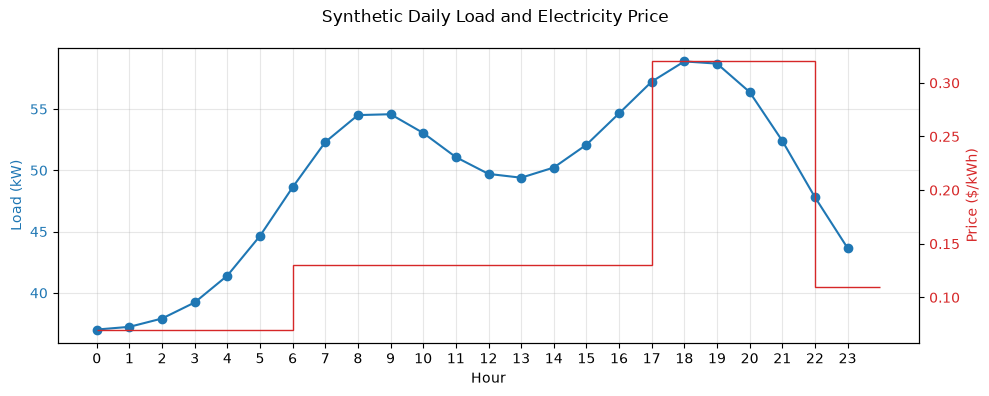

In [4]:
# Step 3. Synthetic one-day load and price data
HOURS = np.arange(24)
TIME_BOUNDARIES = np.arange(25)

morning_peak = 10 * np.exp(-0.5 * ((HOURS - 8) / 2.2) ** 2)
evening_peak = 18 * np.exp(-0.5 * ((HOURS - 19) / 2.8) ** 2)
daily_shape = 42 + 5 * np.sin(2 * np.pi * (HOURS - 6) / 24)
load_kw = np.round(daily_shape + morning_peak + evening_peak, 2)

price_per_kwh = np.full(24, 0.14)
price_per_kwh[(HOURS >= 0) & (HOURS <= 5)] = 0.07
price_per_kwh[(HOURS >= 6) & (HOURS <= 16)] = 0.13
price_per_kwh[(HOURS >= 17) & (HOURS <= 21)] = 0.32
price_per_kwh[(HOURS >= 22) & (HOURS <= 23)] = 0.11

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(HOURS, load_kw, marker="o", label="Load (kW)", color="tab:blue")
ax1.set_xlabel("Hour")
ax1.set_ylabel("Load (kW)", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax1.set_xticks(HOURS)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.stairs(price_per_kwh, TIME_BOUNDARIES, baseline=None, label="Price ($/kWh)", color="tab:red")
ax2.set_ylabel("Price ($/kWh)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

fig.suptitle("Synthetic Daily Load and Electricity Price")
fig.tight_layout()
plt.show()


## Step 4. Build the Battery Environment

The environment is a small simulator. It receives an action, updates battery SOC, computes grid power, and returns the next state and reward.

Important simplifications:

- the time step is $\Delta t=1$ hour and the power values are constant within each step;
- the battery cannot export power back to the grid;
- charging and discharging are clipped to respect SOC limits;
- `one_way_efficiency=0.95` is used for both charging and discharging, so the implied round-trip efficiency is $0.95^2=90.25\%$;
- the energy price is in \$/kWh; the cycling proxy is \$0.005 per kWh of AC-side battery throughput; an impossible charge/discharge command costs \$1 per attempt; and the terminal penalty is \$0.20 per kWh of final-SOC mismatch;
- these cycling, invalid-action, and terminal values are illustrative teaching assumptions, not calibrated asset-life or market-tariff estimates;
- a terminal SOC penalty discourages the agent from ending far away from its initial SOC. In this default example, the battery starts empty, so the agent must learn to charge before it can discharge.

For grid-side charging power $P_t^c\geq0$ and load-side discharging power $P_t^d\geq0$, the stored energy follows

$$E_{t+1}=E_t+\eta P_t^c\Delta t-\frac{P_t^d\Delta t}{\eta}.$$

At each step, reward is `-reward_scale * total_cost`, where total cost is the sum of grid-energy, degradation, invalid-action, and (only on the last step) terminal-SOC costs. The default `reward_scale=0.10` therefore has units of reward units per \$ and changes numerical scale, not the cost-minimizing policy.


In [5]:
class BatteryStorageEnv:
    """Small battery energy-storage environment for a one-day DRL demo."""

    def __init__(
        self,
        load_kw,
        price_per_kwh,
        capacity_kwh=60.0,
        max_power_kw=15.0,
        one_way_efficiency=0.95,
        initial_soc_fraction=0.00,
        terminal_soc_penalty=0.20,
        cycling_cost=0.005,
        reward_scale=0.10,
        invalid_action_penalty=1.00,
    ):
        self.load_kw = np.asarray(load_kw, dtype=np.float32)
        self.price_per_kwh = np.asarray(price_per_kwh, dtype=np.float32)
        self.n_steps = len(self.load_kw)
        self.capacity_kwh = float(capacity_kwh)
        self.max_power_kw = float(max_power_kw)
        self.one_way_efficiency = float(one_way_efficiency)
        self.initial_soc_kwh = float(initial_soc_fraction * capacity_kwh)
        self.terminal_soc_penalty = float(terminal_soc_penalty)
        self.cycling_cost = float(cycling_cost)
        self.reward_scale = float(reward_scale)
        self.invalid_action_penalty = float(invalid_action_penalty)
        self.dt_hours = 1.0

        # Save min/max values so price and load can be scaled into a neural-network-friendly range.
        self.price_min = float(self.price_per_kwh.min())
        self.price_max = float(self.price_per_kwh.max())
        self.load_min = float(self.load_kw.min())
        self.load_max = float(self.load_kw.max())
        self.reset()

    def reset(self):
        self.t = 0
        self.soc_kwh = self.initial_soc_kwh
        self.history = []
        return self._get_state()

    def _normalize(self, value, min_value, max_value):
        return (value - min_value) / (max_value - min_value + 1e-8)

    def _get_state(self):
        # The agent observes normalized time, price, load, and SOC instead of raw engineering units.
        hour_norm = self.t / max(self.n_steps - 1, 1)
        price_norm = self._normalize(self.price_per_kwh[self.t], self.price_min, self.price_max)
        load_norm = self._normalize(self.load_kw[self.t], self.load_min, self.load_max)
        soc_norm = self.soc_kwh / self.capacity_kwh
        return np.array([hour_norm, price_norm, load_norm, soc_norm], dtype=np.float32)

    def step(self, action):
        # One environment step applies the action, updates SOC, computes cost, and returns feedback.
        action_info = ACTIONS[int(action)]
        command = action_info["command"]

        load = float(self.load_kw[self.t])
        price = float(self.price_per_kwh[self.t])
        invalid_action = 0.0
        battery_power_kw = 0.0

        if command > 0:  # charge from grid
            max_grid_charge_kw = min(
                self.max_power_kw,
                (self.capacity_kwh - self.soc_kwh) / (self.one_way_efficiency * self.dt_hours),
            )
            charge_kw = max(0.0, max_grid_charge_kw)
            if charge_kw < 1e-6:
                invalid_action = 1.0
            self.soc_kwh += charge_kw * self.one_way_efficiency * self.dt_hours
            battery_power_kw = charge_kw
            grid_power_kw = load + charge_kw

        elif command < 0:  # discharge to serve local load
            max_discharge_to_load_kw = min(
                self.max_power_kw,
                self.soc_kwh * self.one_way_efficiency / self.dt_hours,
                load,
            )
            discharge_kw = max(0.0, max_discharge_to_load_kw)
            if discharge_kw < 1e-6:
                invalid_action = 1.0
            self.soc_kwh -= discharge_kw / self.one_way_efficiency * self.dt_hours
            battery_power_kw = -discharge_kw
            grid_power_kw = load - discharge_kw

        else:  # idle
            grid_power_kw = load

        # Numerical clipping protects the physical SOC limits after charge/discharge calculations.
        self.soc_kwh = float(np.clip(self.soc_kwh, 0.0, self.capacity_kwh))

        energy_cost = grid_power_kw * price * self.dt_hours
        degradation_cost = self.cycling_cost * abs(battery_power_kw) * self.dt_hours
        invalid_action_cost = self.invalid_action_penalty * invalid_action

        # The terminal cost belongs to the final transition and must be recorded before history is saved.
        done = self.t == self.n_steps - 1
        terminal_cost = 0.0
        if done:
            terminal_cost = self.terminal_soc_penalty * abs(self.soc_kwh - self.initial_soc_kwh)

        total_cost = energy_cost + degradation_cost + invalid_action_cost + terminal_cost
        # DQN maximizes reward, so lower undiscounted dollar cost means higher total reward.
        reward = -total_cost * self.reward_scale

        self.history.append(
            {
                "hour": self.t,
                "action": int(action),
                "action_name": action_info["name"],
                "load_kw": load,
                "price_per_kwh": price,
                "battery_power_kw": battery_power_kw,
                "grid_power_kw": grid_power_kw,
                "soc_kwh": self.soc_kwh,
                "soc_fraction": self.soc_kwh / self.capacity_kwh,
                "energy_cost": energy_cost,
                "degradation_cost": degradation_cost,
                "invalid_action_cost": invalid_action_cost,
                "terminal_cost": terminal_cost,
                "total_cost": total_cost,
                "reward": reward,
                "invalid_action": invalid_action,
            }
        )

        self.t += 1
        if done:
            next_state = np.zeros(4, dtype=np.float32)
        else:
            next_state = self._get_state()

        info = {
            "energy_cost": energy_cost,
            "degradation_cost": degradation_cost,
            "invalid_action_cost": invalid_action_cost,
            "terminal_cost": terminal_cost,
            "total_cost": total_cost,
            "invalid_action": invalid_action,
            "grid_power_kw": grid_power_kw,
            "battery_power_kw": battery_power_kw,
            "soc_kwh": self.soc_kwh,
        }
        return next_state, float(reward), done, info


env = BatteryStorageEnv(load_kw, price_per_kwh)
print("Initial normalized state [hour, price, load, SOC] =", env.reset())


Initial normalized state [hour, price, load, SOC] = [0. 0. 0. 0.]


In [6]:
# Quick environment check with a random policy
state = env.reset()
total_reward = 0.0

done = False
while not done:
    action = np.random.choice(list(ACTIONS.keys()))
    next_state, reward, done, info = env.step(action)
    total_reward += reward
    state = next_state

print(f"Random policy total reward: {total_reward:.2f}")
print("First five environment records:")
for row in env.history[:5]:
    print(row)


Random policy total reward: -19.19
First five environment records:
{'hour': 0, 'action': 2, 'action_name': 'charge', 'load_kw': 37.0099983215332, 'price_per_kwh': 0.07000000029802322, 'battery_power_kw': 15.0, 'grid_power_kw': 52.0099983215332, 'soc_kwh': 14.25, 'soc_fraction': 0.2375, 'energy_cost': 3.6406998980075116, 'degradation_cost': 0.075, 'invalid_action_cost': 0.0, 'terminal_cost': 0.0, 'total_cost': 3.7156998980075118, 'reward': -0.3715699898007512, 'invalid_action': 0.0}
{'hour': 1, 'action': 0, 'action_name': 'discharge', 'load_kw': 37.22999954223633, 'price_per_kwh': 0.07000000029802322, 'battery_power_kw': -13.5375, 'grid_power_kw': 23.692499542236327, 'soc_kwh': 0.0, 'soc_fraction': 0.0, 'energy_cost': 1.6584749750174579, 'degradation_cost': 0.0676875, 'invalid_action_cost': 0.0, 'terminal_cost': 0.0, 'total_cost': 1.7261624750174578, 'reward': -0.17261624750174578, 'invalid_action': 0.0}
{'hour': 2, 'action': 2, 'action_name': 'charge', 'load_kw': 37.90999984741211, 'pr

## Step 5. Define the DQN Agent

A Deep Q-Network (DQN) takes the current state as input and produces one Q-value for each possible action. The largest Q-value indicates the action that currently looks best to the agent.

In this notebook, the neural network is intentionally small:

$$
[state] \rightarrow \text{Dense} \rightarrow \text{ReLU} \rightarrow \text{Dense} \rightarrow \text{ReLU} \rightarrow [Q_{discharge}, Q_{idle}, Q_{charge}].
$$


In [7]:
# One replay item is the standard RL tuple: state, action, reward, next state, and done flag.
Transition = namedtuple("Transition", ("state", "action", "reward", "next_state", "done"))


class ReplayMemory:
    """Fixed-size replay buffer used by DQN."""

    def __init__(self, capacity):
        self.memory = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.memory.append(Transition(state, action, reward, next_state, done))

    def sample(self, batch_size):
        return random.sample(self.memory, batch_size)

    def __len__(self):
        return len(self.memory)


class DQN(nn.Module):
    """Small feed-forward neural network that estimates action values."""

    def __init__(self, state_dim, action_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, action_dim),
        )

    def forward(self, x):
        return self.net(x)


state_dim = 4
action_dim = len(ACTIONS)
policy_net = DQN(state_dim, action_dim).to(device)
target_net = DQN(state_dim, action_dim).to(device)
# The target network changes more slowly, which makes the Bellman target less jumpy during training.
target_net.load_state_dict(policy_net.state_dict())
target_net.eval()

optimizer = optim.Adam(policy_net.parameters(), lr=LEARNING_RATE)
memory = ReplayMemory(capacity=5000)
loss_fn = nn.SmoothL1Loss()

print(policy_net)


DQN(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=3, bias=True)
  )
)


## Step 6. Train the DQN

The DQN training loop uses two standard ideas:

- **epsilon-greedy exploration**: at first, the agent tries many random actions; later, it increasingly uses the neural network;
- **experience replay**: the agent stores past transitions and trains from random mini-batches.

Each episode is one 24-hour day. For a sampled transition, the target is

$$y_t=r_t+(1-d_t)\gamma\max_a Q_{\mathrm{target}}(s_{t+1},a),$$

where $d_t=1$ on the terminal transition. Thus terminal transitions do not bootstrap. Here $\gamma=1$, so the learned return matches the undiscounted sum of all 24 hourly costs.


In [8]:
def select_action(state, epsilon):
    """Choose a random action with probability epsilon, otherwise choose the best DQN action."""
    if random.random() < epsilon:
        return random.randrange(action_dim)

    with torch.no_grad():
        state_tensor = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
        q_values = policy_net(state_tensor)
        return int(q_values.argmax(dim=1).item())


def train_one_step():
    """Train the DQN from one replay-memory mini-batch."""
    if len(memory) < BATCH_SIZE:
        return None

    transitions = memory.sample(BATCH_SIZE)
    batch = Transition(*zip(*transitions))

    state_batch = torch.tensor(np.array(batch.state), dtype=torch.float32, device=device)
    action_batch = torch.tensor(batch.action, dtype=torch.int64, device=device).unsqueeze(1)
    reward_batch = torch.tensor(batch.reward, dtype=torch.float32, device=device)
    next_state_batch = torch.tensor(np.array(batch.next_state), dtype=torch.float32, device=device)
    done_batch = torch.tensor(batch.done, dtype=torch.bool, device=device)

    # Keep only Q(s,a) for the action that was actually taken in each sampled transition.
    q_values = policy_net(state_batch).gather(1, action_batch).squeeze(1)

    # Bellman target: immediate reward plus the next value; done transitions do not bootstrap.
    next_q_values = torch.zeros(BATCH_SIZE, dtype=torch.float32, device=device)
    with torch.no_grad():
        not_done = ~done_batch
        if not_done.any():
            next_q_values[not_done] = target_net(next_state_batch[not_done]).max(dim=1).values

    # GAMMA is 1.0 because dollars later in this finite day are part of the same total-cost objective.
    target_q_values = reward_batch + GAMMA * next_q_values
    loss = loss_fn(q_values, target_q_values)

    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(policy_net.parameters(), max_norm=1.0)
    optimizer.step()

    return float(loss.item())


episode_rewards = []
training_losses = []
epsilon = EPS_START

env = BatteryStorageEnv(load_kw, price_per_kwh)

for episode in range(1, EPISODES + 1):
    state = env.reset()
    total_reward = 0.0
    done = False

    while not done:
        action = select_action(state, epsilon)
        next_state, reward, done, info = env.step(action)
        memory.push(state, action, reward, next_state, done)

        loss = train_one_step()
        if loss is not None:
            training_losses.append(loss)

        state = next_state
        total_reward += reward

    episode_rewards.append(total_reward)
    epsilon = max(EPS_END, epsilon * EPS_DECAY)

    if episode % TARGET_UPDATE == 0:
        # Periodically copy the learned network into the target network.
        target_net.load_state_dict(policy_net.state_dict())

    if episode % 50 == 0:
        recent_avg = np.mean(episode_rewards[-20:])
        print(f"Episode {episode:3d} | recent avg reward = {recent_avg:8.2f} | epsilon = {epsilon:.3f}")

print("Training finished.")


Episode  50 | recent avg reward =   -19.67 | epsilon = 0.470


Episode 100 | recent avg reward =   -19.09 | epsilon = 0.221


Episode 150 | recent avg reward =   -19.03 | epsilon = 0.104


Episode 200 | recent avg reward =   -19.04 | epsilon = 0.050


Episode 250 | recent avg reward =   -18.43 | epsilon = 0.050


Episode 300 | recent avg reward =   -18.27 | epsilon = 0.050
Training finished.


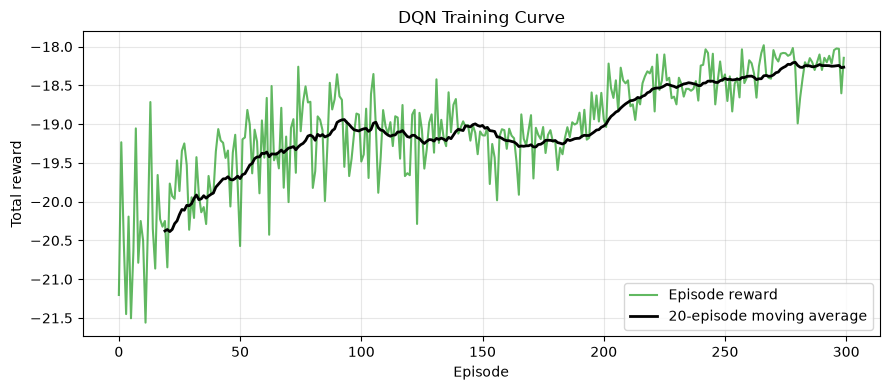

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(episode_rewards, color="tab:green", alpha=0.75, label="Episode reward")
if len(episode_rewards) >= 20:
    moving_avg = np.convolve(episode_rewards, np.ones(20) / 20, mode="valid")
    ax.plot(np.arange(19, len(episode_rewards)), moving_avg, color="black", linewidth=2, label="20-episode moving average")
ax.set_xlabel("Episode")
ax.set_ylabel("Total reward")
ax.set_title("DQN Training Curve")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## Step 7. Evaluate the Training-Day Rollout

After training, we run the greedy learned policy on the **same fixed load and price arrays used in every training episode** and compare it with two transparent baselines:

- **No battery**: the load is fully served by the grid;
- **Straightforward SOC-cycle rule**: ignore time, load, and price. At or below the lower SOC switching threshold, enter charging mode and keep charging until the upper threshold is reached; then enter discharging mode and keep discharging until SOC is at or below the lower switching threshold. If the battery starts between the thresholds, discharge first. The default thresholds are 0% and 100%.

This is a **training-day rollout**, not a held-out test and not evidence of generalization to unseen days. The hand-written rule neither reads nor predicts electricity prices; its remembered charge/discharge mode prevents it from reversing direction after a single step. It is an intentionally simple operational reference, so the comparison is diagnostic rather than a claim that learning must always beat a rule. We report every reward component. Complete cost equals grid-energy + degradation + invalid-action + terminal-SOC cost, and `total_reward = -reward_scale * complete_cost`.


In [10]:
def baseline_no_battery(load_kw, price_per_kwh, dt_hours=1.0):
    """Daily grid-energy cost with no battery for one-hour or user-specified time steps."""
    load_kw = np.asarray(load_kw, dtype=float)
    price_per_kwh = np.asarray(price_per_kwh, dtype=float)
    return float(np.sum(load_kw * price_per_kwh * dt_hours))


class StraightforwardCyclePolicy:
    """Price-blind full-cycle rule with remembered charge/discharge mode."""

    def __init__(self, lower_soc_fraction=0.0, upper_soc_fraction=1.0, soc_tolerance_kwh=1e-9):
        if not 0.0 <= lower_soc_fraction < upper_soc_fraction <= 1.0:
            raise ValueError("Require 0 <= lower SOC < upper SOC <= 1.")
        self.lower_soc_fraction = float(lower_soc_fraction)
        self.upper_soc_fraction = float(upper_soc_fraction)
        self.soc_tolerance_kwh = float(soc_tolerance_kwh)
        self.mode = None

    def reset(self, env):
        lower_soc_kwh = self.lower_soc_fraction * env.capacity_kwh
        # If there is usable stored energy at the start, discharge it first.
        self.mode = "charge" if env.soc_kwh <= lower_soc_kwh + self.soc_tolerance_kwh else "discharge"

    def __call__(self, state, env):
        del state  # This rule uses only physical SOC and its remembered mode.
        if self.mode is None:
            self.reset(env)

        lower_soc_kwh = self.lower_soc_fraction * env.capacity_kwh
        upper_soc_kwh = self.upper_soc_fraction * env.capacity_kwh

        if self.mode == "charge" and env.soc_kwh >= upper_soc_kwh - self.soc_tolerance_kwh:
            self.mode = "discharge"
        elif self.mode == "discharge" and env.soc_kwh <= lower_soc_kwh + self.soc_tolerance_kwh:
            self.mode = "charge"

        return 2 if self.mode == "charge" else 0


def dqn_policy(state, env):
    """Greedy policy from the trained DQN."""
    with torch.no_grad():
        state_tensor = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
        return int(policy_net(state_tensor).argmax(dim=1).item())


def run_policy(policy_fn, label):
    # Use the same environment and accounting for every storage policy.
    """Run a policy for one training day and return all cost and reward components."""
    eval_env = BatteryStorageEnv(load_kw, price_per_kwh)
    state = eval_env.reset()
    if hasattr(policy_fn, "reset"):
        policy_fn.reset(eval_env)
    done = False
    accumulated_reward = 0.0

    while not done:
        action = policy_fn(state, eval_env)
        next_state, reward, done, info = eval_env.step(action)
        accumulated_reward += reward
        state = next_state

    cost_keys = ("energy_cost", "degradation_cost", "invalid_action_cost", "terminal_cost")
    totals = {key: float(sum(row[key] for row in eval_env.history)) for key in cost_keys}
    complete_cost = float(sum(totals.values()))
    history_reward = float(sum(row["reward"] for row in eval_env.history))

    # These checks make any future reward-accounting mismatch fail visibly.
    assert np.isclose(accumulated_reward, history_reward, atol=1e-10)
    assert np.isclose(history_reward, -eval_env.reward_scale * complete_cost, atol=1e-10)

    result = {
        "label": label,
        "history": eval_env.history,
        **totals,
        "complete_cost": complete_cost,
        "total_reward": history_reward,
        "invalid_count": int(sum(row["invalid_action"] for row in eval_env.history)),
        "final_soc_kwh": float(eval_env.soc_kwh),
        "initial_soc_fraction": eval_env.initial_soc_kwh / eval_env.capacity_kwh,
    }
    return result


no_battery_cost = baseline_no_battery(load_kw, price_per_kwh)
reference_env = BatteryStorageEnv(load_kw, price_per_kwh)
no_battery_result = {
    "label": "No battery",
    "energy_cost": no_battery_cost,
    "degradation_cost": 0.0,
    "invalid_action_cost": 0.0,
    "terminal_cost": 0.0,
    "complete_cost": no_battery_cost,
    "invalid_count": 0,
    "final_soc_kwh": 0.0,
    "total_reward": -reference_env.reward_scale * no_battery_cost,
}
cycle_policy = StraightforwardCyclePolicy(lower_soc_fraction=0.0, upper_soc_fraction=1.0)
cycle_result = run_policy(cycle_policy, "Straightforward cycle")
dqn_result = run_policy(dqn_policy, "DQN")

print("Training-day rollout (cost columns are dollars):")
header = (
    f"{'Policy':<22} {'Energy':>8} {'Degrad.':>8} {'Invalid':>8} {'Terminal':>9} "
    f"{'Complete':>9} {'Bad acts':>8} {'SOC kWh':>10} {'Reward':>9}"
)
print(header)
for result in (no_battery_result, cycle_result, dqn_result):
    print(
        f"{result['label']:<22} {result['energy_cost']:8.2f} {result['degradation_cost']:8.2f} "
        f"{result['invalid_action_cost']:8.2f} {result['terminal_cost']:9.2f} "
        f"{result['complete_cost']:9.2f} {result['invalid_count']:8d} "
        f"{result['final_soc_kwh']:10.2f} {result['total_reward']:9.2f}"
    )
print()
print("Straightforward cycle action schedule:")
print([row["action_name"] for row in cycle_result["history"]])
print("DQN action schedule:")
print([row["action_name"] for row in dqn_result["history"]])


Training-day rollout (cost columns are dollars):
Policy                   Energy  Degrad.  Invalid  Terminal  Complete Bad acts    SOC kWh    Reward
No battery               191.58     0.00     0.00      0.00    191.58        0       0.00    -19.16
Straightforward cycle    205.91     1.59     0.00      8.84    216.34        0      44.21    -21.63
DQN                      179.27     0.92     0.00      0.00    180.19        0       0.00    -18.02

Straightforward cycle action schedule:
['charge', 'charge', 'charge', 'charge', 'charge', 'discharge', 'discharge', 'discharge', 'discharge', 'charge', 'charge', 'charge', 'charge', 'charge', 'discharge', 'discharge', 'discharge', 'discharge', 'charge', 'charge', 'charge', 'charge', 'charge', 'discharge']
DQN action schedule:
['idle', 'idle', 'idle', 'charge', 'charge', 'charge', 'discharge', 'discharge', 'idle', 'idle', 'idle', 'idle', 'idle', 'charge', 'charge', 'charge', 'charge', 'discharge', 'discharge', 'discharge', 'discharge', 'idle', '

## Step 8. Visualize Results

The plots below compare the no-battery case, the price-blind straightforward SOC-cycle rule, and the learned DQN policy on the training day. SOC and cumulative complete cost use time boundaries 0 through 24, including their initial values at time 0; hourly load, power, and price use hours 0 through 23. The no-battery SOC and battery-power traces are zero because no storage device is used in that baseline.


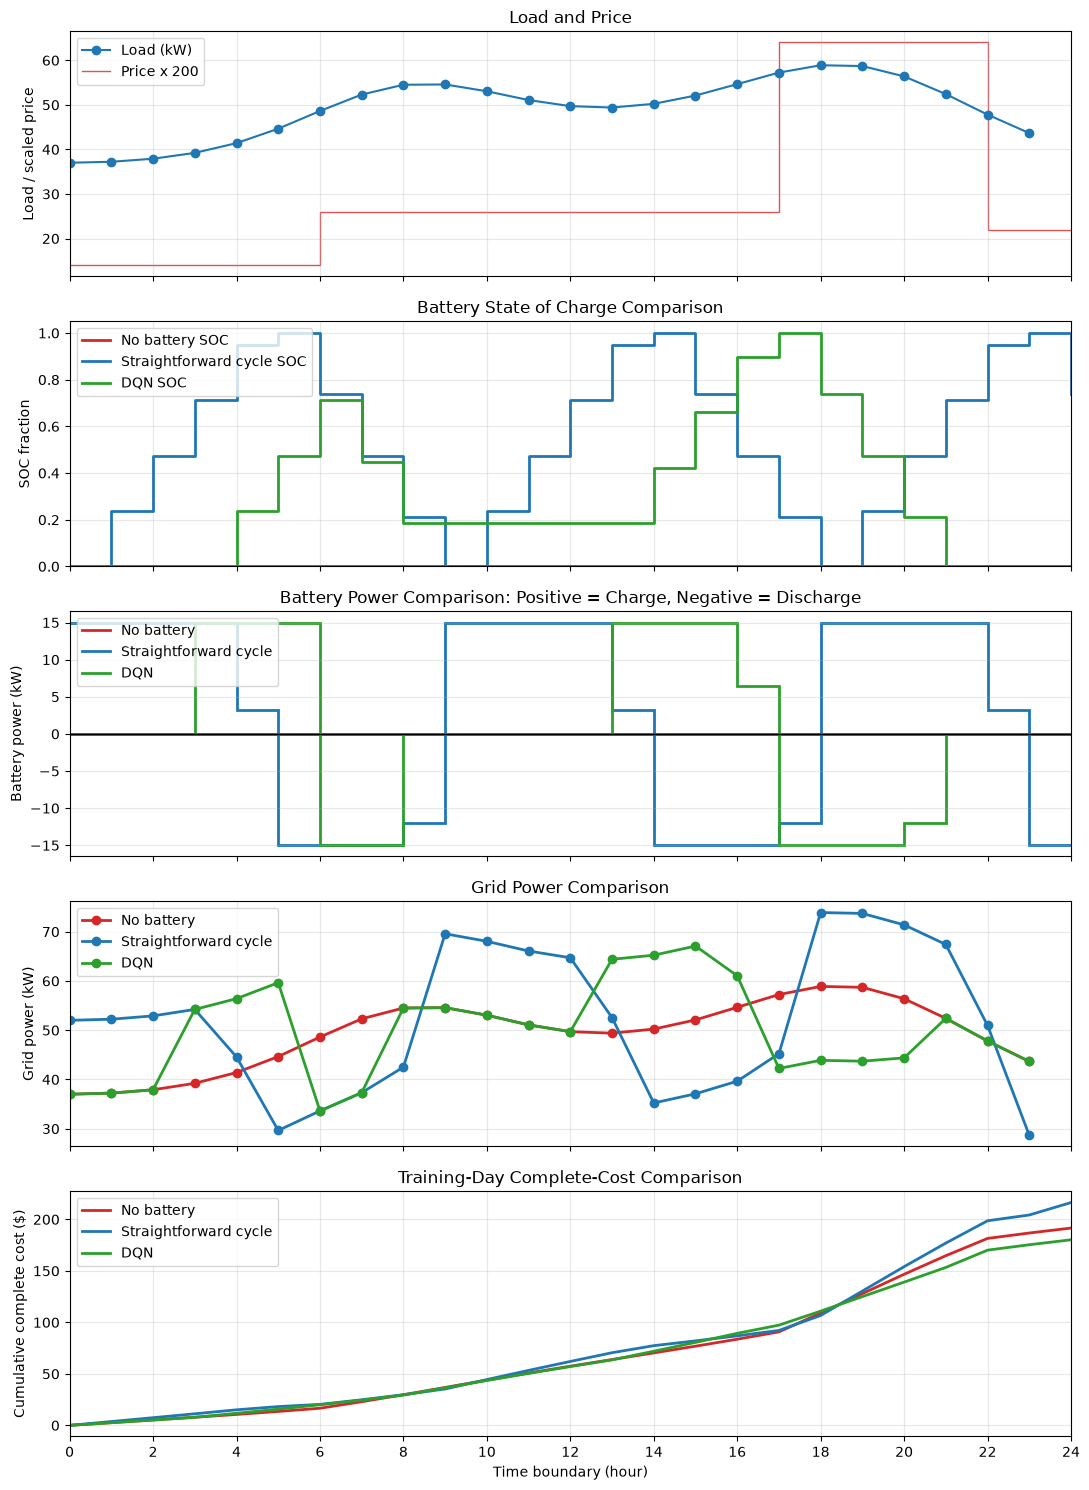

In [11]:
def history_values(result, key):
    return np.array([row[key] for row in result["history"]], dtype=float)


# State and cumulative-cost traces live on the 25 time boundaries, including the initial value.
assert len(TIME_BOUNDARIES) == len(HOURS) + 1
no_battery_soc = np.zeros(len(TIME_BOUNDARIES), dtype=float)
cycle_soc = np.r_[cycle_result["initial_soc_fraction"], history_values(cycle_result, "soc_fraction")]
dqn_soc = np.r_[dqn_result["initial_soc_fraction"], history_values(dqn_result, "soc_fraction")]

no_battery_power = np.zeros_like(HOURS, dtype=float)
cycle_power = history_values(cycle_result, "battery_power_kw")
dqn_power = history_values(dqn_result, "battery_power_kw")

no_battery_grid = load_kw.astype(float)
cycle_grid = history_values(cycle_result, "grid_power_kw")
dqn_grid = history_values(dqn_result, "grid_power_kw")

no_battery_cost_cumulative = np.r_[0.0, np.cumsum(no_battery_grid * price_per_kwh * 1.0)]
cycle_cost_cumulative = np.r_[0.0, np.cumsum(history_values(cycle_result, "total_cost"))]
dqn_cost_cumulative = np.r_[0.0, np.cumsum(history_values(dqn_result, "total_cost"))]

fig, axes = plt.subplots(5, 1, figsize=(11, 15), sharex=True)

axes[0].plot(HOURS, load_kw, marker="o", label="Load (kW)", color="tab:blue")
axes[0].stairs(price_per_kwh * 200, TIME_BOUNDARIES, baseline=None, label="Price x 200", color="tab:red", alpha=0.8)
axes[0].set_ylabel("Load / scaled price")
axes[0].set_title("Load and Price")
axes[0].legend(loc="upper left")
axes[0].grid(True, alpha=0.3)

axes[1].step(TIME_BOUNDARIES, no_battery_soc, where="post", color="tab:red", linewidth=2, label="No battery SOC")
axes[1].step(TIME_BOUNDARIES, cycle_soc, where="post", color="tab:blue", linewidth=2, label="Straightforward cycle SOC")
axes[1].step(TIME_BOUNDARIES, dqn_soc, where="post", color="tab:green", linewidth=2, label="DQN SOC")
axes[1].set_ylabel("SOC fraction")
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Battery State of Charge Comparison")
axes[1].legend(loc="upper left")
axes[1].grid(True, alpha=0.3)

axes[2].stairs(no_battery_power, TIME_BOUNDARIES, baseline=None, color="tab:red", linewidth=2, label="No battery")
axes[2].stairs(cycle_power, TIME_BOUNDARIES, baseline=None, color="tab:blue", linewidth=2, label="Straightforward cycle")
axes[2].stairs(dqn_power, TIME_BOUNDARIES, baseline=None, color="tab:green", linewidth=2, label="DQN")
axes[2].axhline(0, color="black", linewidth=1)
axes[2].set_ylabel("Battery power (kW)")
axes[2].set_title("Battery Power Comparison: Positive = Charge, Negative = Discharge")
axes[2].legend(loc="upper left")
axes[2].grid(True, axis="y", alpha=0.3)

axes[3].plot(HOURS, no_battery_grid, marker="o", label="No battery", linewidth=2, color="tab:red")
axes[3].plot(HOURS, cycle_grid, marker="o", label="Straightforward cycle", linewidth=2, color="tab:blue")
axes[3].plot(HOURS, dqn_grid, marker="o", label="DQN", linewidth=2, color="tab:green")
axes[3].set_ylabel("Grid power (kW)")
axes[3].set_title("Grid Power Comparison")
axes[3].legend(loc="upper left")
axes[3].grid(True, alpha=0.3)

axes[4].plot(TIME_BOUNDARIES, no_battery_cost_cumulative, label="No battery", linewidth=2, color="tab:red")
axes[4].plot(TIME_BOUNDARIES, cycle_cost_cumulative, label="Straightforward cycle", linewidth=2, color="tab:blue")
axes[4].plot(TIME_BOUNDARIES, dqn_cost_cumulative, label="DQN", linewidth=2, color="tab:green")
axes[4].set_xlabel("Time boundary (hour)")
axes[4].set_ylabel("Cumulative complete cost ($)")
axes[4].set_title("Training-Day Complete-Cost Comparison")
axes[4].legend(loc="upper left")
axes[4].grid(True, alpha=0.3)
axes[4].set_xlim(0, 24)
axes[4].set_xticks(np.arange(0, 25, 2))

fig.tight_layout()
plt.show()


## Further Reading

For the original DQN algorithm and a broader view of how model-free reinforcement learning can be connected with practical microgrid control problems, see:

V. Mnih et al., "Human-level control through deep reinforcement learning," *Nature*, vol. 518, pp. 529-533, Feb. 2015, doi: [10.1038/nature14236](https://doi.org/10.1038/nature14236).

B. She, F. Li, H. Cui, J. Zhang, and R. Bo, "Fusion of Microgrid Control With Model-Free Reinforcement Learning: Review and Vision," *IEEE Transactions on Smart Grid*, vol. 14, no. 4, pp. 3232-3245, Jul. 2023, doi: [10.1109/TSG.2022.3222323](https://doi.org/10.1109/TSG.2022.3222323).
